Actividad fundamental 2

    Ejercicio 1 .-  Uso de Pandas, Matplotlib, Numpy

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [80]:
# Importar dataset de Vino tinto desde URL.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')

In [81]:
# Mostrar las primeras 5 filas y el resumen estadístico.
print(df.head())
df.describe()

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [82]:
# Identificar si existen valores nulos y eliminarlos.
print(df.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [83]:
# Crear una nueva columna llamada is_good que sea 1 si la quality es mayor a 6,
# y 0 en caso contrario.
df['is_good'] = (df['quality'] > 6).astype(int)
print(df['is_good'])

0       0
1       0
2       0
3       0
4       0
       ..
1594    0
1595    0
1596    0
1597    0
1598    0
Name: is_good, Length: 1599, dtype: int64


In [84]:
# Filtrar el DataFrame para mostrar solo los vinos
# con un nivel de alcohol superior al 11%
dfAlcoholAlto = df[df['alcohol'] > 11]
print(dfAlcoholAlto.head())

     fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
45             4.6              0.52         0.15             2.1      0.054   
95             4.7              0.60         0.17             2.3      0.058   
131            5.6              0.50         0.09             2.3      0.049   
132            5.6              0.50         0.09             2.3      0.049   
142            5.2              0.34         0.00             1.8      0.050   

     free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
45                   8.0                  65.0   0.9934  3.90       0.56   
95                  17.0                 106.0   0.9932  3.85       0.60   
131                 17.0                  99.0   0.9937  3.63       0.63   
132                 17.0                  99.0   0.9937  3.63       0.63   
142                 27.0                  63.0   0.9916  3.68       0.79   

     alcohol  quality  is_good  
45      13.1        4        

In [85]:
# Convertir las columnas de características
# en una matriz de NumPy llamada X.
X = df.drop(columns=['quality', 'is_good']).values
print(X)

[[ 7.4    0.7    0.    ...  3.51   0.56   9.4  ]
 [ 7.8    0.88   0.    ...  3.2    0.68   9.8  ]
 [ 7.8    0.76   0.04  ...  3.26   0.65   9.8  ]
 ...
 [ 6.3    0.51   0.13  ...  3.42   0.75  11.   ]
 [ 5.9    0.645  0.12  ...  3.57   0.71  10.2  ]
 [ 6.     0.31   0.47  ...  3.39   0.66  11.   ]]


In [86]:
# Calcular la media y la desviación estándar de cada columna.
Xmean = np.mean(X, axis= 0)
Xstd = np.std(X, axis= 0)
print('Media:\n', Xmean, '\n')
print('Desviación estándar:\n', Xstd)

Media:
 [ 8.31963727  0.52782051  0.27097561  2.5388055   0.08746654 15.87492183
 46.46779237  0.99674668  3.3111132   0.65814884 10.42298311] 

Desviación estándar:
 [1.74055180e+00 1.79003704e-01 1.94740214e-01 1.40948711e+00
 4.70505826e-02 1.04568856e+01 3.28850367e+01 1.88674370e-03
 1.54338181e-01 1.69453967e-01 1.06533430e+00]


In [87]:
# Normalización Z-Score
Xnormal = (X - Xmean) / Xstd
print(Xnormal)

[[-0.52835961  0.96187667 -1.39147228 ...  1.28864292 -0.57920652
  -0.96024611]
 [-0.29854743  1.96744245 -1.39147228 ... -0.7199333   0.1289504
  -0.58477711]
 [-0.29854743  1.29706527 -1.18607043 ... -0.33117661 -0.04808883
  -0.58477711]
 ...
 [-1.1603431  -0.09955388 -0.72391627 ...  0.70550789  0.54204194
   0.54162988]
 [-1.39015528  0.65462046 -0.77526673 ...  1.6773996   0.30598963
  -0.20930812]
 [-1.33270223 -1.21684919  1.02199944 ...  0.51112954  0.01092425
   0.54162988]]


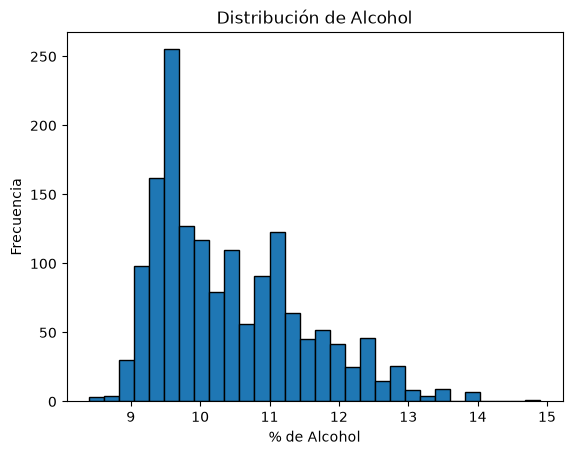

In [88]:
# Crear un histograma de la variable alcohol para ver su distribución.
plt.hist(df['alcohol'], bins=30, edgecolor='black')
plt.title('Distribución de Alcohol')
plt.xlabel('% de Alcohol')
plt.ylabel('Frecuencia')
plt.show()

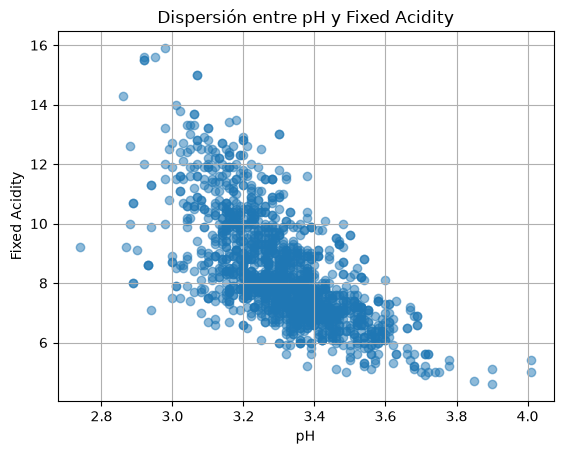

In [89]:
# Realiza un gráfico de dispersión entre pH y fixed acidity. ¿Notas alguna tendencia?
plt.scatter(df['pH'], df['fixed acidity'], alpha=0.5)
plt.title('Dispersión entre pH y Fixed Acidity')
plt.xlabel('pH')
plt.ylabel('Fixed Acidity')
plt.grid(True)
plt.show()

Tendencia: NO SÉ, NO SOY 100TÍFICO

In [90]:
# Genera un gráfico de cajas que compare el nivel de alcohol según la quality.
#plt.boxplot()